# Lecture 2 — Channels, Distances, and Statistics (UnitaryLab companion)

This notebook demonstrates the core estimation and distance concepts of Lecture 2
using the UnitaryLab simulator (v1.1.4). Run the cells top to bottom.

Contents:
1. The Hadamard test — estimating $\mathrm{Re}\,\langle\psi|U|\psi\rangle$ from measurements
2. Empirical error vs. the Hoeffding bound as the number of shots grows
3. Trace distance between two single-qubit states from their density matrices

In [1]:
import numpy as np
from unitarylab.core import Circuit

# Render matplotlib figures inline and headless (works under nbconvert --execute).
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

rng = np.random.default_rng(2)

## 1. The Hadamard test

To estimate the *real part* of $\langle\psi|U|\psi\rangle$ for a unitary $U$ and a
state $|\psi\rangle$, we use an ancilla qubit:

1. Put the ancilla in $|+\rangle$ with a Hadamard.
2. Apply *controlled*-$U$ to the system, controlled on the ancilla.
3. Apply a second Hadamard to the ancilla and measure it.

Then $\Pr[\text{ancilla}=0]-\Pr[\text{ancilla}=1] = \mathrm{Re}\,\langle\psi|U|\psi\rangle$.

We take a concrete example: system state $|\psi\rangle = R_y(\theta)|0\rangle$ and
$U = R_z(\phi)$. Here qubit 0 is the system and qubit 1 is the ancilla.

In [2]:
theta = 0.7      # prepares the system state |psi> = Ry(theta)|0>
phi   = 1.1       # U = Rz(phi)

# Exact target value: <psi|U|psi>
psi = np.array([np.cos(theta/2), np.sin(theta/2)], dtype=complex)   # Ry(theta)|0>
U   = np.array([[np.exp(-1j*phi/2), 0],[0, np.exp(1j*phi/2)]])       # Rz(phi)
exact = (psi.conj() @ U @ psi)
print('exact <psi|U|psi> =', np.round(exact, 4))
print('Re part           =', np.round(exact.real, 4))

exact <psi|U|psi> = (0.8525-0.3998j)
Re part           = 0.8525


### Building the Hadamard-test circuit

We prepare the system, then apply controlled-$R_z$ using `append(sub, target=[system], control=[ancilla])`.

In [3]:
def hadamard_test_prob0(theta, phi, shots):
    sub = Circuit(1, name='U'); sub.rz(phi, 0)          # U = Rz(phi) on the system
    qc = Circuit(2, name='hadamard_test')               # q0 = system, q1 = ancilla
    qc.ry(theta, 0)                                     # prepare |psi> on the system
    qc.h(1)                                             # ancilla -> |+>
    qc.append(sub, target=[0], control=[1])             # controlled-U
    qc.h(1)                                             # interfere
    qc.measure(1, 0)                                    # measure ancilla only
    res = qc.execute(backend='numpy', dtype=np.complex128, shots=shots)
    return res.counts

counts = hadamard_test_prob0(theta, phi, shots=20000)
print('ancilla counts:', counts)
# counts keys read q1 q0; we measured only clbit 0 (the ancilla). Aggregate by ancilla bit.
n0 = sum(v for k, v in counts.items() if k[-1] == '0')
n1 = sum(v for k, v in counts.items() if k[-1] == '1')
est = (n0 - n1) / (n0 + n1)
print('estimated Re<psi|U|psi> =', round(est, 4), ' exact =', round(exact.real, 4))
assert abs(est - exact.real) < 0.05, 'Hadamard-test estimate should be close to exact'
print('assert passed: estimate within 0.05 of exact')

ancilla counts: {'x0': 18524, 'x1': 1476}
estimated Re<psi|U|psi> = 0.8524  exact = 0.8525
assert passed: estimate within 0.05 of exact


## 2. Empirical error vs. the Hoeffding bound

The Hadamard test returns a $\pm 1$ random variable whose mean is
$\mathrm{Re}\,\langle\psi|U|\psi\rangle$. By Hoeffding's inequality the empirical
mean over $N$ shots concentrates: with high probability the error is
$\mathcal{O}(1/\sqrt N)$. Concretely, the standard deviation of the mean is
$\sigma/\sqrt N$ with $\sigma=\sqrt{1-\mu^2}\le 1$, so a $1/\sqrt N$ envelope
bounds the typical error. We plot empirical error against this envelope.

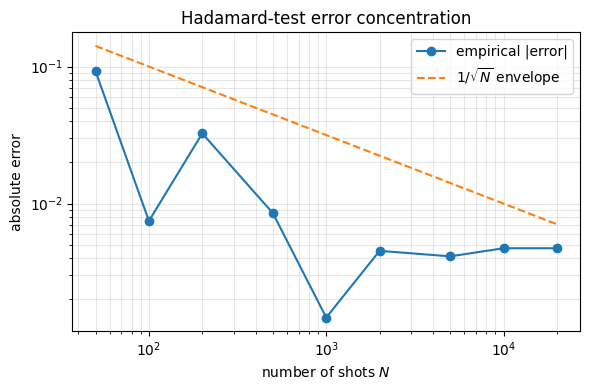

errors: [0.0925, 0.0075, 0.0325, 0.0085, 0.0015, 0.0045, 0.0041, 0.0047, 0.0047]


In [4]:
shot_list = [50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]
errors = []
for N in shot_list:
    counts = hadamard_test_prob0(theta, phi, shots=N)
    n0 = sum(v for k, v in counts.items() if k[-1] == '0')
    n1 = sum(v for k, v in counts.items() if k[-1] == '1')
    est = (n0 - n1) / (n0 + n1)
    errors.append(abs(est - exact.real))

Ns = np.array(shot_list, dtype=float)
plt.figure(figsize=(6,4))
plt.loglog(Ns, errors, 'o-', label='empirical |error|')
plt.loglog(Ns, 1.0/np.sqrt(Ns), '--', label=r'$1/\sqrt{N}$ envelope')
plt.xlabel('number of shots $N$'); plt.ylabel('absolute error')
plt.title('Hadamard-test error concentration'); plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
print('errors:', [round(e,4) for e in errors])

## 3. Trace distance between two single-qubit states

The trace distance $T(\rho,\sigma)=\tfrac12\|\rho-\sigma\|_1
=\tfrac12\sum_i|\lambda_i|$ (sum over eigenvalues of $\rho-\sigma$) measures the
maximum distinguishing probability between two states. We compute it directly
from the density matrices with numpy.

In [5]:
def density_matrix(state):
    v = np.asarray(state, dtype=complex).ravel()
    return np.outer(v, v.conj())

def trace_distance(rho, sigma):
    diff = rho - sigma
    eig = np.linalg.eigvalsh(diff)     # Hermitian
    return 0.5 * np.sum(np.abs(eig))

# |0> and |1> are perfectly distinguishable: trace distance 1.
rho0 = density_matrix([1, 0])
rho1 = density_matrix([0, 1])
print('T(|0>,|1>) =', round(trace_distance(rho0, rho1), 6))
assert abs(trace_distance(rho0, rho1) - 1.0) < 1e-9

# |0> and |+> overlap, so trace distance is 1/sqrt(2).
plus = np.array([1, 1]) / np.sqrt(2)
T = trace_distance(rho0, density_matrix(plus))
print('T(|0>,|+>) =', round(T, 6), ' (expected 1/sqrt(2) =', round(1/np.sqrt(2), 6), ')')
assert abs(T - 1/np.sqrt(2)) < 1e-9
print('asserts passed: trace distances match analytic values')

T(|0>,|1>) = 1.0
T(|0>,|+>) = 0.707107  (expected 1/sqrt(2) = 0.707107 )
asserts passed: trace distances match analytic values


### Your turn
- Change $U$ to $R_x(\phi)$ (edit `sub.rz` to `sub.rx`) and re-derive the exact
  target; confirm the Hadamard test still tracks it.
- Add a second measurement basis to estimate the *imaginary* part
  (apply an $S^\dagger$ on the ancilla before the final Hadamard).
- Compute the trace distance between two random single-qubit pure states and
  verify $T=\sqrt{1-|\langle\psi|\phi\rangle|^2}$.